<a href="https://colab.research.google.com/github/AdityaR28/OSS4008A---Introduction-to-Remote-Sensing-and-Applications/blob/main/students/devon_clermont-gauer/code/unet_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 03: U-Net Training and Evaluation (Project 11)
#**Name:** Devon Clermont-Gauer

#Trains a U-Net (ResNet-34 encoder, ImageNet-pretrained) to classify each Sentinel-2 pixel as water or not water, using the tiles from notebook 01 and band statistics from notebook 02. Evaluates on the hand-corrected test set against the NDWI baseline and Dynamic World.

#**How to run:** Runtime → Change runtime type → T4 GPU, then run all cells in order.

In [2]:
# Cell 1: install, connect Drive, copy the dataset locally for fast training
!pip install -q segmentation-models-pytorch

from google.colab import drive
drive.mount('/content/drive')

import os, glob, json, time, shutil, random
from collections import defaultdict
import numpy as np
import rasterio
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp     # ready-made U-Net with pretrained encoders
import matplotlib.pyplot as plt

DRIVE_DS = '/content/drive/MyDrive/water_dataset'
LOCAL_DS = '/content/water_dataset'                  # local copy: much faster to read than Drive
MODELS   = '/content/drive/MyDrive/water_models'     # saved models and results (survive disconnects)
os.makedirs(MODELS, exist_ok=True)

# Remove any partial copy from a failed run, then copy (skipping previews and Google Docs)
if os.path.exists(LOCAL_DS) and not os.path.exists(f'{LOCAL_DS}/band_stats.json'):
    shutil.rmtree(LOCAL_DS)
if not os.path.exists(LOCAL_DS):
    print('Copying dataset from Drive to local disk...')
    shutil.copytree(DRIVE_DS, LOCAL_DS,
                    ignore=shutil.ignore_patterns('previews', '*.gdoc'))

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)
if device == 'cpu':
    print('WARNING: no GPU. Runtime → Change runtime type → T4 GPU, then restart.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda


In [3]:
# Cell 2: read tiles, rescale bands, augment training tiles
stats = json.load(open(f'{LOCAL_DS}/band_stats.json'))       # from notebook 02 (training tiles only)
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]

class WaterTiles(Dataset):
    """Pairs of (5-band image, water mask) tiles."""
    def __init__(self, image_paths, mask_paths, augment=False):
        self.images, self.masks, self.augment = image_paths, mask_paths, augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        with rasterio.open(self.images[i]) as s:
            img = s.read().astype(np.float32)                    # (5, 256, 256)
        with rasterio.open(self.masks[i]) as s:
            mask = (s.read(1) == 1).astype(np.float32)[None]     # (1, 256, 256), 1 = water
        img = (img - MEAN) / STD                                 # rescale each band to a similar range

        if self.augment:                                         # random flips/rotations (water looks the same)
            if random.random() < 0.5:
                img, mask = img[:, :, ::-1], mask[:, :, ::-1]
            if random.random() < 0.5:
                img, mask = img[:, ::-1, :], mask[:, ::-1, :]
            k = random.randint(0, 3)
            img, mask = np.rot90(img, k, axes=(1, 2)), np.rot90(mask, k, axes=(1, 2))
        return torch.from_numpy(img.copy()), torch.from_numpy(mask.copy())

def split_paths(split, mask_folder='masks'):
    """Image and mask paths for a split; keeps only tiles that have a mask."""
    imgs = sorted(glob.glob(f'{LOCAL_DS}/{split}/images/*.tif'))
    pairs = [(p, p.replace('/images/', f'/{mask_folder}/')) for p in imgs]
    pairs = [(a, b) for a, b in pairs if os.path.exists(b)]
    return [a for a, _ in pairs], [b for _, b in pairs]

def region_of(path):
    return os.path.basename(path).rsplit('_r', 1)[0]

In [4]:
# Cell 3: training, validation and corrected test sets
train_ds = WaterTiles(*split_paths('train'), augment=True)
val_ds   = WaterTiles(*split_paths('val'))
test_ds  = WaterTiles(*split_paths('test', 'masks_corrected'))   # the 40 hand-corrected tiles

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2)
val_dl   = DataLoader(val_ds,   batch_size=16, num_workers=2)

print(f'Train: {len(train_ds)}  Val: {len(val_ds)}  Test (corrected): {len(test_ds)}')

Train: 396  Val: 112  Test (corrected): 40


In [5]:
# Cell 4: U-Net with a pretrained ResNet-34 encoder, adapted to 5 bands
model = smp.Unet('resnet34', encoder_weights='imagenet', in_channels=5, classes=1).to(device)

dice = smp.losses.DiceLoss(mode='binary', from_logits=True)   # handles the water/land imbalance
bce  = nn.BCEWithLogitsLoss()                                 # standard per-pixel loss
def loss_fn(logits, y):
    return dice(logits, y) + bce(logits, y)

opt = torch.optim.Adam(model.parameters(), lr=1e-4)
print('Model ready.')

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model ready.


In [6]:
# Cell 5: train, scoring validation IoU each epoch; save the best model to Drive
def counts(logits, y):
    """True positives, false positives, false negatives for water."""
    p, t = torch.sigmoid(logits) > 0.5, y > 0.5
    return (p & t).sum().item(), (p & ~t).sum().item(), (~p & t).sum().item()

def evaluate(dl):
    model.eval()
    tp = fp = fn = 0
    total, n = 0.0, 0
    with torch.no_grad():
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total += loss_fn(logits, y).item() * len(x)
            n += len(x)
            a, b, c = counts(logits, y)
            tp, fp, fn = tp + a, fp + b, fn + c
    return total / n, tp / (tp + fp + fn + 1e-9)

CKPT, HIST = f'{MODELS}/unet_resnet34_best.pth', f'{MODELS}/history.json'
EPOCHS, PATIENCE = 50, 8          # stop if validation IoU doesn't improve for 8 epochs
history = {'train_loss': [], 'val_loss': [], 'val_iou': []}
best, wait = 0.0, 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, total, n = time.time(), 0.0, 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        opt.step()
        total += loss.item() * len(x)
        n += len(x)

    val_loss, val_iou = evaluate(val_dl)
    history['train_loss'].append(total / n)
    history['val_loss'].append(val_loss)
    history['val_iou'].append(val_iou)

    note = ''
    if val_iou > best:
        best, wait = val_iou, 0
        torch.save(model.state_dict(), CKPT)
        note = '  <- best, saved'
    else:
        wait += 1
    print(f'Epoch {epoch:2d} | train loss {total/n:.4f} | val loss {val_loss:.4f} '
          f'| val IoU {val_iou:.3f} | {time.time()-t0:.0f}s{note}')
    json.dump(history, open(HIST, 'w'))

    if wait >= PATIENCE:
        print(f'No improvement for {PATIENCE} epochs: stopping.')
        break

print(f'Best validation IoU: {best:.3f}  (saved to {CKPT})')

Epoch  1 | train loss 1.2859 | val loss 1.2669 | val IoU 0.330 | 10s  <- best, saved
Epoch  2 | train loss 1.0144 | val loss 0.9518 | val IoU 0.596 | 8s  <- best, saved
Epoch  3 | train loss 0.8738 | val loss 0.8154 | val IoU 0.793 | 8s  <- best, saved
Epoch  4 | train loss 0.8044 | val loss 0.7237 | val IoU 0.870 | 8s  <- best, saved
Epoch  5 | train loss 0.7203 | val loss 0.6677 | val IoU 0.868 | 9s
Epoch  6 | train loss 0.6783 | val loss 0.6393 | val IoU 0.857 | 10s
Epoch  7 | train loss 0.6251 | val loss 0.5742 | val IoU 0.902 | 8s  <- best, saved
Epoch  8 | train loss 0.5664 | val loss 0.5176 | val IoU 0.909 | 8s  <- best, saved
Epoch  9 | train loss 0.5317 | val loss 0.4894 | val IoU 0.928 | 10s  <- best, saved
Epoch 10 | train loss 0.5047 | val loss 0.4387 | val IoU 0.916 | 8s
Epoch 11 | train loss 0.4628 | val loss 0.4255 | val IoU 0.932 | 10s  <- best, saved
Epoch 12 | train loss 0.4247 | val loss 0.3807 | val IoU 0.943 | 8s  <- best, saved
Epoch 13 | train loss 0.4093 | val l

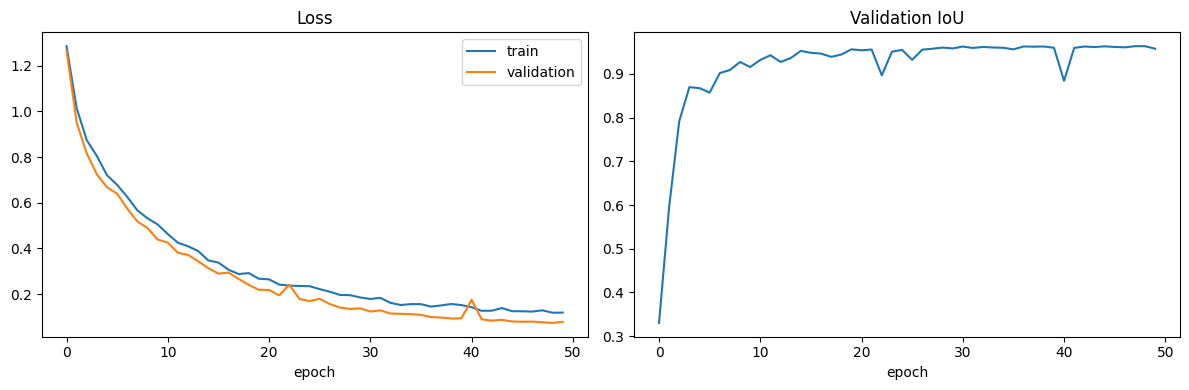

In [7]:
# Cell 6: plot loss and validation IoU over epochs
h = json.load(open(HIST))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h['train_loss'], label='train'); ax[0].plot(h['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(h['val_iou']); ax[1].set_title('Validation IoU'); ax[1].set_xlabel('epoch')
plt.tight_layout()
plt.savefig(f'{MODELS}/training_curves.png', dpi=120)
plt.show()

In [8]:
# Cell 7: score the best model on the corrected test set; compare to NDWI and Dynamic World
model.load_state_dict(torch.load(CKPT, map_location=device))
model.eval()

def summarize(totals):
    rows = {}
    for r, (tp, fp, fn) in sorted(totals.items()):
        rows[r] = {'iou': tp / (tp + fp + fn + 1e-9),
                   'f1': 2 * tp / (2 * tp + fp + fn + 1e-9),
                   'precision': tp / (tp + fp + 1e-9),
                   'recall': tp / (tp + fn + 1e-9)}
    regions = [r for r in rows if r != 'ALL']
    rows['REGION_AVG'] = {k: float(np.mean([rows[r][k] for r in regions])) for k in rows['ALL']}
    return rows

# U-Net vs corrected masks
unet = defaultdict(lambda: np.zeros(3))
dw   = defaultdict(lambda: np.zeros(3))
with torch.no_grad():
    for i in range(len(test_ds)):
        x, y = test_ds[i]
        r = region_of(test_ds.images[i])
        c = counts(model(x[None].to(device)), y[None].to(device))
        unet[r] += c; unet['ALL'] += c

        # Dynamic World mask as a "prediction", vs the corrected mask
        dw_path = test_ds.images[i].replace('/images/', '/masks/')
        with rasterio.open(dw_path) as s:
            d = torch.from_numpy((s.read(1) == 1)[None, None])
        t = y[None] > 0.5
        c = ((d & t).sum().item(), (d & ~t).sum().item(), (~d & t).sum().item())
        dw[r] += c; dw['ALL'] += c

unet_rows, dw_rows = summarize(unet), summarize(dw)
ndwi = json.load(open(f'{LOCAL_DS}/results/ndwi_baseline.json'))['vs_corrected']
ndwi_regions = [r for r in ndwi if r != 'ALL']
ndwi['REGION_AVG'] = {'iou': float(np.mean([ndwi[r]['iou'] for r in ndwi_regions]))}

print(f"{'region':12} {'NDWI':>7} {'DynWorld':>9} {'U-Net':>7}   (IoU vs corrected masks)")
for r in list(unet_rows):
    print(f"{r:12} {ndwi.get(r, {}).get('iou', float('nan')):7.3f} "
          f"{dw_rows[r]['iou']:9.3f} {unet_rows[r]['iou']:7.3f}")

json.dump({'unet': unet_rows, 'dynamic_world': dw_rows}, open(f'{MODELS}/test_results.json', 'w'), indent=2)
print('\nSaved:', f'{MODELS}/test_results.json')

region          NDWI  DynWorld   U-Net   (IoU vs corrected masks)
ALL            0.609     0.929   0.891
iqaluit        0.738     0.959   0.917
kejimkujik     0.496     0.893   0.900
minnedosa      0.168     0.837   0.760
winnipeg       0.469     0.934   0.783
REGION_AVG     0.468     0.905   0.840

Saved: /content/drive/MyDrive/water_models/test_results.json


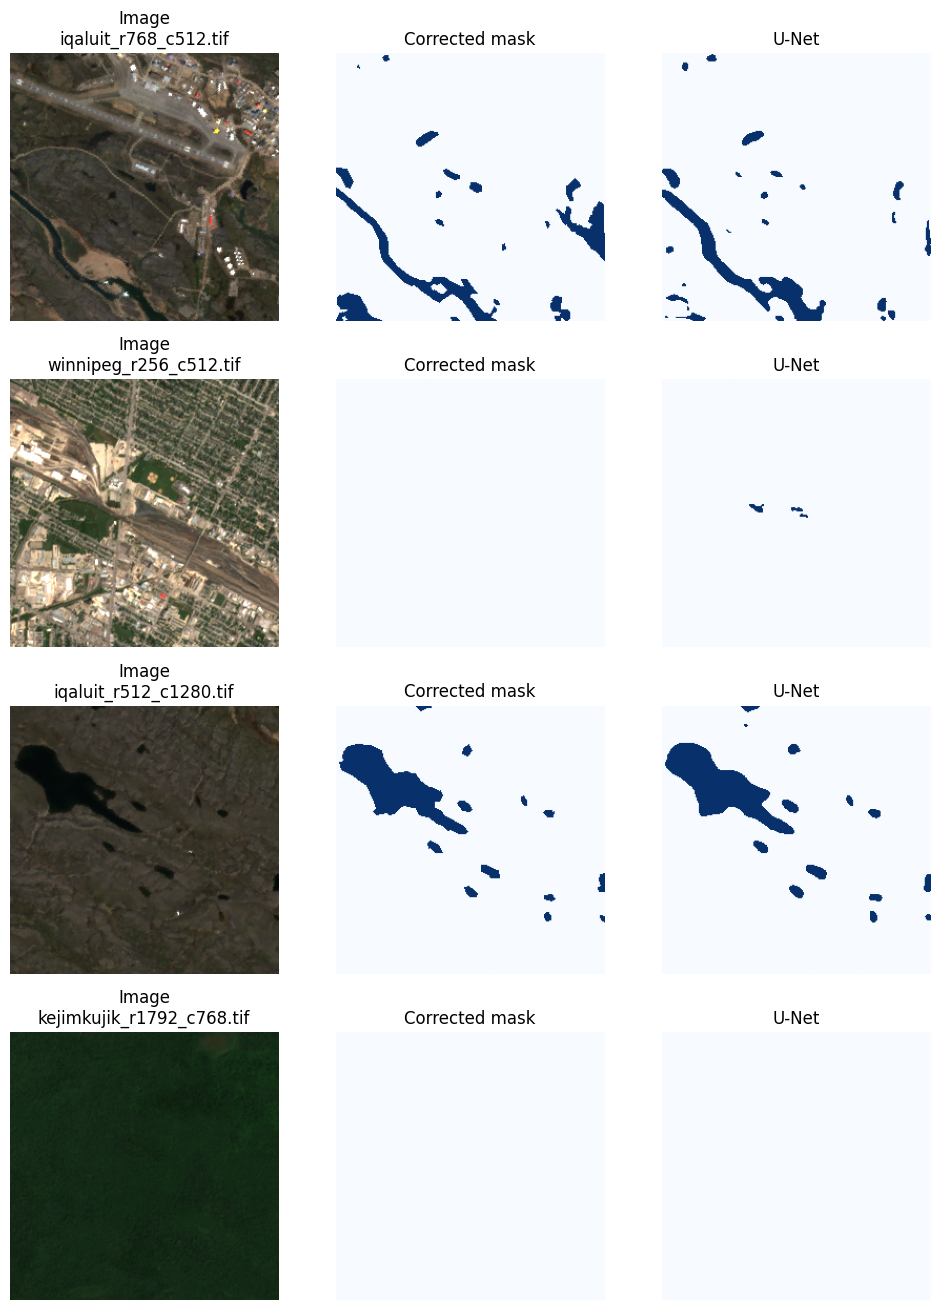

In [9]:
# Cell 8: show image, corrected mask and U-Net prediction for a few test tiles
picks = random.Random(1).sample(range(len(test_ds)), 4)
fig, ax = plt.subplots(len(picks), 3, figsize=(10, 3.3 * len(picks)))
with torch.no_grad():
    for row, i in enumerate(picks):
        x, y = test_ds[i]
        pred = (torch.sigmoid(model(x[None].to(device)))[0, 0] > 0.5).cpu().numpy()
        with rasterio.open(test_ds.images[i]) as s:
            rgb = np.clip(s.read([3, 2, 1]).transpose(1, 2, 0) / 3000, 0, 1)
        for col, (im, title) in enumerate([(rgb, 'Image'), (y[0], 'Corrected mask'), (pred, 'U-Net')]):
            ax[row, col].imshow(im, cmap=None if col == 0 else 'Blues')
            ax[row, col].set_title(f'{title}' + (f'\n{os.path.basename(test_ds.images[i])}' if col == 0 else ''))
            ax[row, col].axis('off')
plt.tight_layout()
plt.savefig(f'{MODELS}/example_predictions.png', dpi=100)
plt.show()